In [31]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [32]:
df = pd.read_csv("auto_mpg.csv")
print(df.shape); df.info()
display(df.describe(include="all").T)
print(df.isna().sum())

(398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mpg,398.0,NaN,NaN,NaN,23.514573,7.815984,9.0,17.5,23.0,29.0,46.6
cylinders,398.0,NaN,NaN,NaN,5.454774,1.701004,3.0,4.0,4.0,8.0,8.0
displacement,398.0,NaN,NaN,NaN,193.425879,104.269838,68.0,104.25,148.5,262.0,455.0
horsepower,392.0,NaN,NaN,NaN,104.469388,38.49116,46.0,75.0,93.5,126.0,230.0
weight,398.0,NaN,NaN,NaN,2970.424623,846.841774,1613.0,2223.75,2803.5,3608.0,5140.0
acceleration,398.0,NaN,NaN,NaN,15.56809,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,NaN,NaN,NaN,76.01005,3.697627,70.0,73.0,76.0,79.0,82.0
origin,398,3,usa,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,398,305,ford pinto,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [33]:
X = df.drop(columns=["mpg", "name"]).copy()
y = df["mpg"].copy()

In [34]:
if pd.api.types.is_numeric_dtype(X["origin"]):
    X["origin"] = X["origin"].map({
        1: "usa",
        2: "europe",
        3: "japan"
    })


X["origin"] = X["origin"].astype("string")

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [36]:
train_df = X_train.copy()
train_df["mpg"] = y_train

print("Full dataset shape:", df.shape)
print("Training features shape:", X_train.shape)
print("Test features shape:", X_test.shape)

display(train_df.head())
train_df.info()
display(train_df.describe(include="all").T)
print("\nMissing values in training data:")
display(train_df.isna().sum().to_frame("Missing Count"))

Full dataset shape: (398, 9)
Training features shape: (318, 7)
Test features shape: (80, 7)


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
3,8,304.0,150.0,3433,12.0,70,usa,16.0
18,4,97.0,88.0,2130,14.5,70,japan,27.0
376,4,91.0,68.0,2025,18.2,82,japan,37.0
248,4,91.0,60.0,1800,16.4,78,japan,36.1
177,4,115.0,95.0,2694,15.0,75,europe,23.0


<class 'pandas.core.frame.DataFrame'>
Index: 318 entries, 3 to 102
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cylinders     318 non-null    int64  
 1   displacement  318 non-null    float64
 2   horsepower    313 non-null    float64
 3   weight        318 non-null    int64  
 4   acceleration  318 non-null    float64
 5   model_year    318 non-null    int64  
 6   origin        318 non-null    string 
 7   mpg           318 non-null    float64
dtypes: float64(4), int64(3), string(1)
memory usage: 22.4 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
cylinders,318.0,NaN,NaN,NaN,5.430818,1.684947,3.0,4.0,4.0,6.0,8.0
displacement,318.0,NaN,NaN,NaN,191.904088,102.983802,68.0,98.5,148.5,259.5,455.0
horsepower,313.0,NaN,NaN,NaN,103.284345,37.361097,46.0,75.0,92.0,122.0,225.0
weight,318.0,NaN,NaN,NaN,2969.015723,840.617729,1613.0,2220.0,2822.5,3597.25,5140.0
acceleration,318.0,NaN,NaN,NaN,15.639937,2.763269,8.0,13.9,15.5,17.3,24.8
model_year,318.0,NaN,NaN,NaN,76.103774,3.603177,70.0,73.0,76.0,79.0,82.0
origin,318,3,usa,196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mpg,318.0,NaN,NaN,NaN,23.608176,7.930574,9.0,17.5,22.45,29.725,46.6



Missing values in training data:


,Missing Count
cylinders,0
displacement,0
horsepower,5
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


In [37]:
numeric_df = df.select_dtypes(include="number")

Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_counts = (
    (numeric_df < lower) | (numeric_df > upper)
).sum()

display(outlier_counts.to_frame("Potential outliers"))

,Potential outliers
mpg,1
cylinders,0
displacement,0
horsepower,10
weight,0
acceleration,7
model_year,0


The Auto MPG dataset contains 398 observations and nine columns, including the target variable `mpg`. Horsepower contains six missing values, while the other columns have no missing values according to the dataset description. MPG has a mean of approximately 23.51 and a median of 23.0, indicating that the center of the distribution is around 23 MPG. The middle 50% of MPG values range from 17.5 to 29.0. 

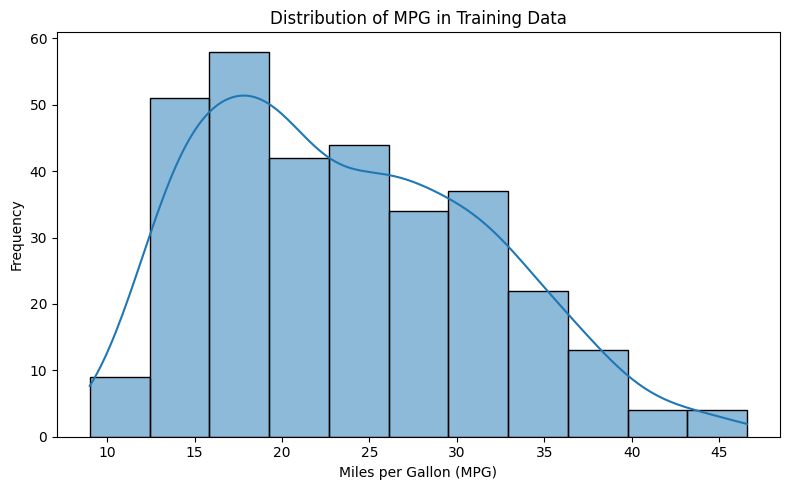

In [38]:
plt.figure(figsize=(8, 5))
sns.histplot(data=train_df, x="mpg", kde=True)
plt.title("Distribution of MPG in Training Data")
plt.xlabel("Miles per Gallon (MPG)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

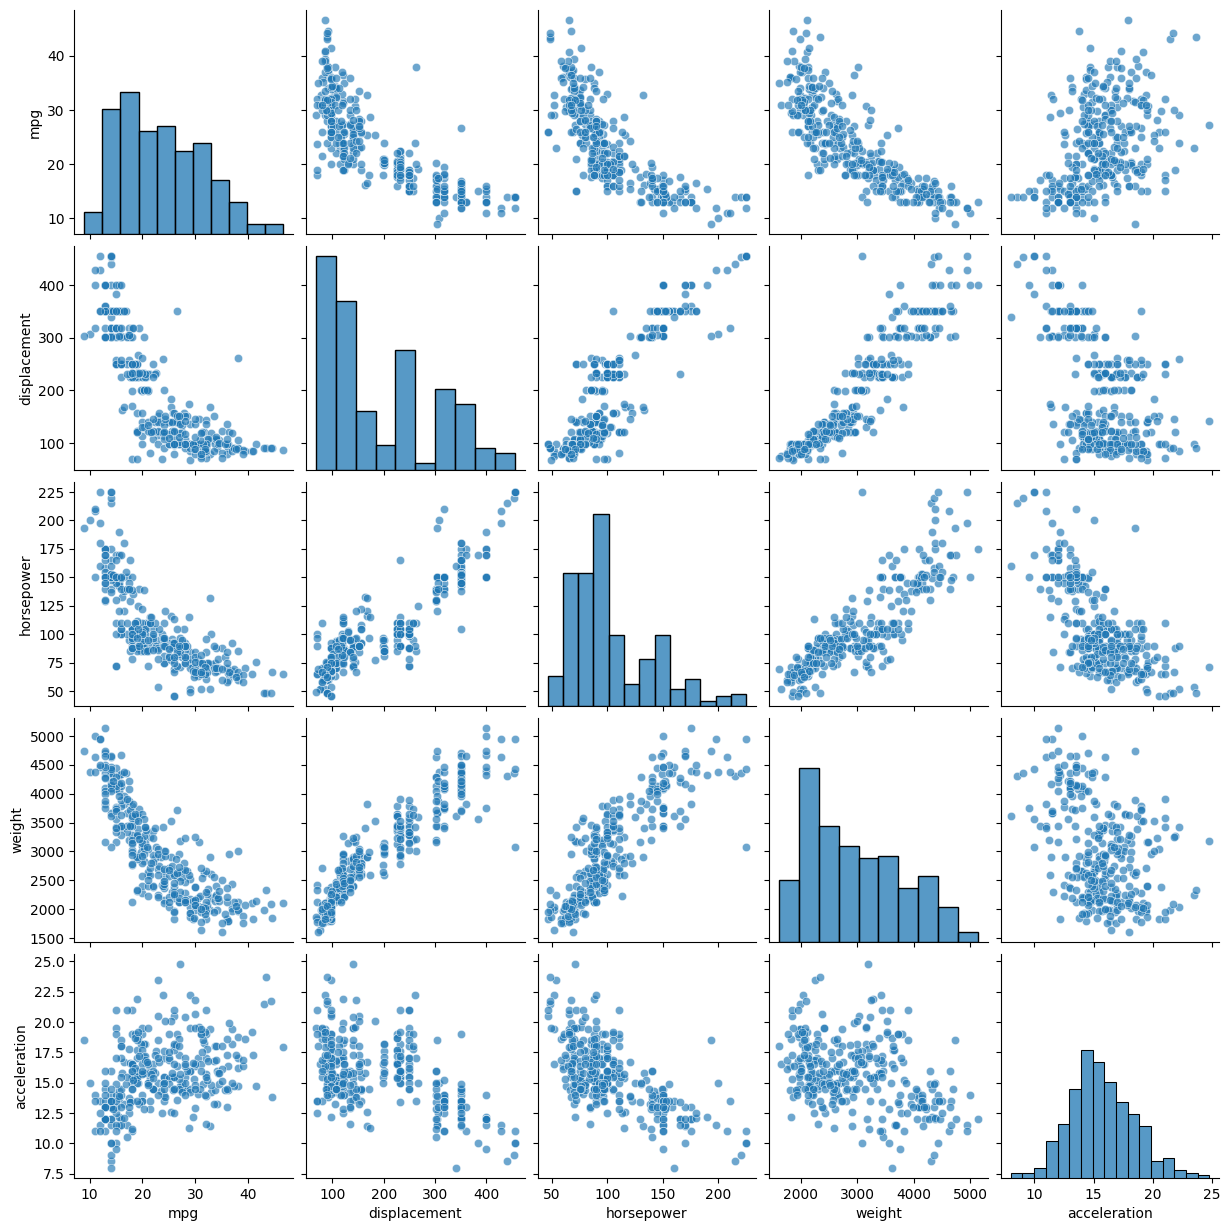

In [39]:
pair_cols = [
    "mpg", "displacement", "horsepower",
    "weight", "acceleration"
]

sns.pairplot(
    train_df[pair_cols],
    diag_kind="hist",
    plot_kws={"alpha": 0.65}
)
plt.show()

The pairplot reveals negative relationships between MPG and weight, displacement, and horsepower. Heavier vehicles and vehicles with larger or more powerful engines generally have lower fuel efficiency. Displacement, horsepower, and weight also show positive relationships with one another. These patterns indicate that the features may be useful for predicting MPG, although the relationships are not perfectly linear.

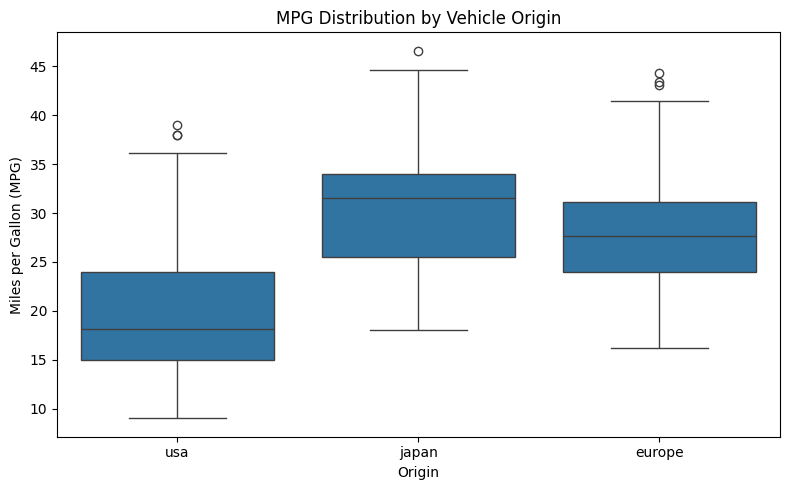

In [40]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_df, x="origin", y="mpg")
plt.title("MPG Distribution by Vehicle Origin")
plt.xlabel("Origin")
plt.ylabel("Miles per Gallon (MPG)")
plt.tight_layout()
plt.show()

The boxplot shows that fuel efficiency differs across vehicle origins. Japanese cars have the highest median MPG, followed by European cars, while American cars have the lowest median MPG. The groups also show different spreads and several potential high-MPG outliers. Therefore, origin may be a useful categorical feature for predicting MPG.

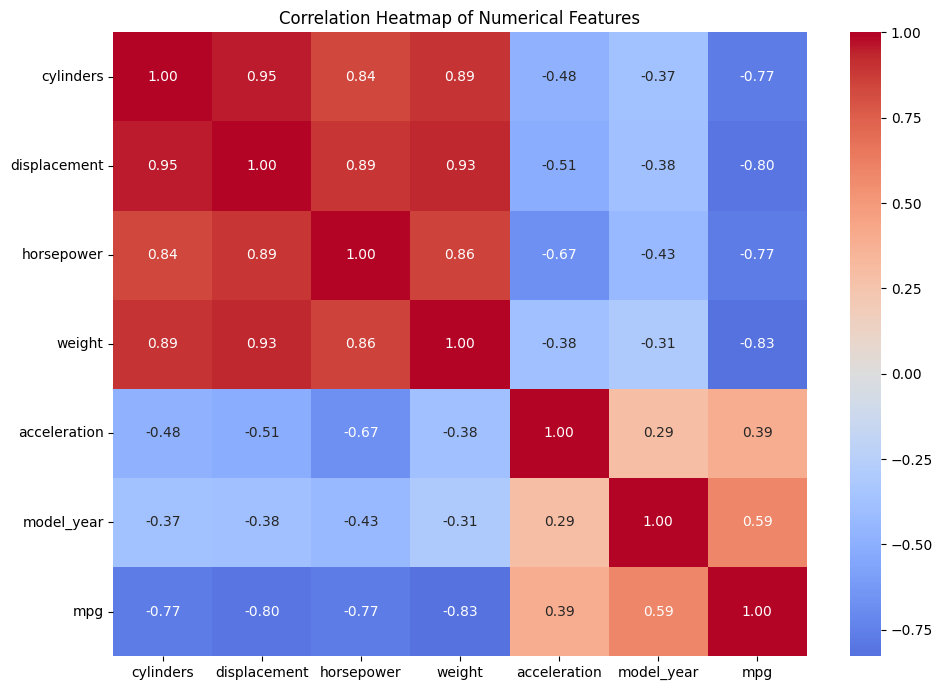

Correlations with MPG:


,Correlation with MPG
weight,-0.827333
displacement,-0.801543
horsepower,-0.772308
cylinders,-0.770459
model_year,0.586743
acceleration,0.390101


Strongest feature-to-feature correlations:


,,Correlation
cylinders,displacement,0.951825
displacement,weight,0.929479
cylinders,weight,0.893808
displacement,horsepower,0.888972
horsepower,weight,0.855325
cylinders,horsepower,0.839187
horsepower,acceleration,-0.672726
displacement,acceleration,-0.512604
cylinders,acceleration,-0.479743
horsepower,model_year,-0.430757


In [41]:
numeric_cols = train_df.select_dtypes(include="number").columns

corr = train_df[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Correlations with the target
print("Correlations with MPG:")
display(
    corr["mpg"]
    .drop("mpg")
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .to_frame("Correlation with MPG")
)

# Strong correlations between input features
feature_corr = corr.drop(index="mpg", columns="mpg")
pairs = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
).stack().sort_values(key=lambda s: s.abs(), ascending=False)

print("Strongest feature-to-feature correlations:")
display(pairs.head(10).to_frame("Correlation"))

The correlation heatmap shows that weight (−0.83), displacement (−0.80), cylinders (−0.77), and horsepower (−0.77) have strong negative linear relationships with MPG. Model year has a positive correlation of +0.59 with MPG. Strong positive correlations between cylinders, displacement, horsepower, and weight indicate potential multicollinearity.

In [42]:
num_cols = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

cat_cols = ["origin"]

We will use median imputation for horsepower because the median is less sensitive to extreme values than the mean. Horsepower may contain unusually high values and also has a relatively wide range, from 46 to 230, making the median a more robust choice in the presence of extreme values. Since only 6 out of 398 values are missing, median imputation is a reasonable

In [43]:
# A Pipeline connects multiple operations in a particular order.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

pre = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

pipe = Pipeline([
    ("pre", pre),
    ("model", LinearRegression())
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross-validated baseline RMSE
cv_rmse = -cross_val_score(
    pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

print("RMSE for each fold:", cv_rmse)
print("Mean CV RMSE:", cv_rmse.mean())
print("Standard deviation of CV RMSE:", cv_rmse.std())

RMSE for each fold: [3.60024449 3.79792989 3.26343659 3.18849675 3.53857434]
Mean CV RMSE: 3.477736410259831
Standard deviation of CV RMSE: 0.22397202378885658


In [44]:
def report(model, X, y, name="model"):
    predictions = model.predict(X)

    return {
        "model": name,
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "MAE": mean_absolute_error(y, predictions),
        "R2": r2_score(y, predictions)
    }

# Fit on all training data
pipe.fit(X_train, y_train)

# Evaluate once on the untouched test data
test_results = report(
    pipe,
    X_test,
    y_test,
    "LinearRegression baseline"
)

print("Mean CV RMSE:", round(cv_rmse.mean(), 4))
print("CV RMSE standard deviation:", round(cv_rmse.std(), 4))

display(pd.DataFrame([test_results]).round(4))

Mean CV RMSE: 3.4777
CV RMSE standard deviation: 0.224


,model,RMSE,MAE,R2
0,LinearRegression baseline,2.8877,2.2882,0.8449


Q1. Why did we split before imputing?
We split the dataset before imputing to prevent data leakage. If we calculate the median using the full dataset, information from the test set influences the preprocessing. By placing the imputer inside a Pipeline, its median is learned only from the training portion of each cross-validation fold or the final training set.

Q2. Why does one-hot encoding use handle_unknown="ignore"?
The setting prevents errors when the model encounters a categorical value that was not present during training. The encoder represents the unseen category using zeros for the learned category columns, allowing prediction to continue.

Q3. Why does KNN care about scaling more than a decision tree does?
KNN uses distances to identify neighboring observations. Features with larger numerical scales can dominate those distances, even when they are not more important. Scaling helps each feature contribute on a more comparable basis. Decision trees use feature thresholds and splits rather than distance calculations, so their predictions generally do not require feature scaling.

Q4. If you add StandardScaler before Linear Regression, do predictions change? Do coefficients change? Test it.


In [45]:
# Pipeline without scaling, but with the same imputation and encoding
num_pipeline_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

pre_unscaled = ColumnTransformer([
    ("num", num_pipeline_unscaled, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

pipe_unscaled = Pipeline([
    ("pre", pre_unscaled),
    ("model", LinearRegression())
])

# Fit both pipelines on the training set
pipe.fit(X_train, y_train)
pipe_unscaled.fit(X_train, y_train)

# Compare predictions on training data
pred_scaled = pipe.predict(X_train)
pred_unscaled = pipe_unscaled.predict(X_train)

print(
    "Maximum absolute prediction difference:",
    np.max(np.abs(pred_scaled - pred_unscaled))
)

# Compare numerical feature coefficients
scaled_names = pipe.named_steps["pre"].get_feature_names_out()
unscaled_names = pipe_unscaled.named_steps["pre"].get_feature_names_out()

coef_comparison = pd.DataFrame({
    "feature": scaled_names,
    "scaled_coefficient": pipe.named_steps["model"].coef_
}).merge(
    pd.DataFrame({
        "feature": unscaled_names,
        "unscaled_coefficient": pipe_unscaled.named_steps["model"].coef_
    }),
    on="feature"
)

display(coef_comparison.round(4))

Maximum absolute prediction difference: 4.831690603168681e-13


,feature,scaled_coefficient,unscaled_coefficient
0,num__cylinders,-0.2790,-0.1659
1,num__displacement,2.0358,0.0198
2,num__horsepower,-0.5448,-0.0147
3,num__weight,-5.9121,-0.0070
4,num__acceleration,0.1857,0.0673
5,num__model_year,2.9708,0.8258
6,cat__origin_europe,1.0741,1.0741
7,cat__origin_japan,0.7997,0.7997
8,cat__origin_usa,-1.8738,-1.8738


Q4: Effect of StandardScaler on Linear Regression

After comparing Linear Regression with and without StandardScaler, the maximum absolute prediction difference ws veery very small, which is effectively zero. Therefore, scaling did not meaningfully change the predictions.

However, the numerical coefficients changed because StandardScaler transformed the numerical features into standardized units. For example, the weight coefficient changed from −0.0070 to −5.9121. The categorical coefficients remained unchanged because the one-hot encoded features were not scaled.

This experiment shows that ordinary Linear Regression generally produces equivalent predictions with or without numerical feature scaling, although the coefficient values as the model can represent essentially the same relationship, so it produces the same prediction.